In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd, torch, yaml
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, recall_score, accuracy_score

from src.training.imbalance import (compute_class_weights, class_counts,
                                    oversample_indices, undersample_indices, make_weighted_sampler)
from src.training.augmentation import augment_batch

sns.set_theme(style="whitegrid")
P = yaml.safe_load((PROJECT_ROOT / "configs" / "preprocessing.yaml").read_text(encoding="utf-8"))
CLASSES, SEED = P["classes"], P["seed"]
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
d = np.load(PROJECT_ROOT / P["output"]["dataset"])
X, y, split = d["X"], d["y"], d["split"]
y_tr, y_va, y_te = y[split == "train"], y[split == "val"], y[split == "test"]
print({k: class_counts(v, 4).tolist() for k, v in [("train", y_tr), ("val", y_va), ("test", y_te)]})

{'train': [35924, 749, 2991, 385], 'val': [9930, 195, 797, 29], 'test': [44245, 1837, 3220, 388]}


In [2]:
n = class_counts(y_tr, 4)
tab = pd.DataFrame({"n_train": n}, index=CLASSES)
for m in ("balanced", "sqrt", "effective"):
    tab[f"w_{m}"] = compute_class_weights(y_tr, 4, m).numpy()
print(tab.round(3))
w = compute_class_weights(y_tr, 4, "balanced").numpy()
print("\nMasse de poids par classe (n_c * w_c), doit être égale à N/C :", (n * w).round(1), "| N/C =", n.sum() / 4)

   n_train  w_balanced  w_sqrt  w_effective
N    35924    0.279000   0.726        0.960
S      749   13.367000   5.025        1.821
V     2991    3.347000   2.515        1.011
F      385   26.006001   7.009        3.004

Masse de poids par classe (n_c * w_c), doit être égale à N/C : [10012.2 10012.2 10012.3 10012.2] | N/C = 10012.25


In [3]:
for name, yy in [("val", y_va), ("test", y_te)]:
    pred = np.zeros_like(yy)
    print(f"{name}: accuracy = {accuracy_score(yy, pred):.4f} | macro-F1 = {f1_score(yy, pred, average='macro', zero_division=0):.4f} "
          f"| recall par classe = {recall_score(yy, pred, average=None, labels=[0,1,2,3], zero_division=0).round(3)}")

val: accuracy = 0.9068 | macro-F1 = 0.2378 | recall par classe = [1. 0. 0. 0.]
test: accuracy = 0.8904 | macro-F1 = 0.2355 | recall par classe = [1. 0. 0. 0.]


                                     N      S      V      F
aucune                           35924    749   2991    385
poids dans la perte (masse n·w)  10012  10012  10012  10012
oversampling complet             35924  35924  35924  35924
undersampling (max 2000)          2000    749   2000    385
sampler power=1                   9919  10122  10058   9950
sampler power=0.5                26012   3758   7486   2793


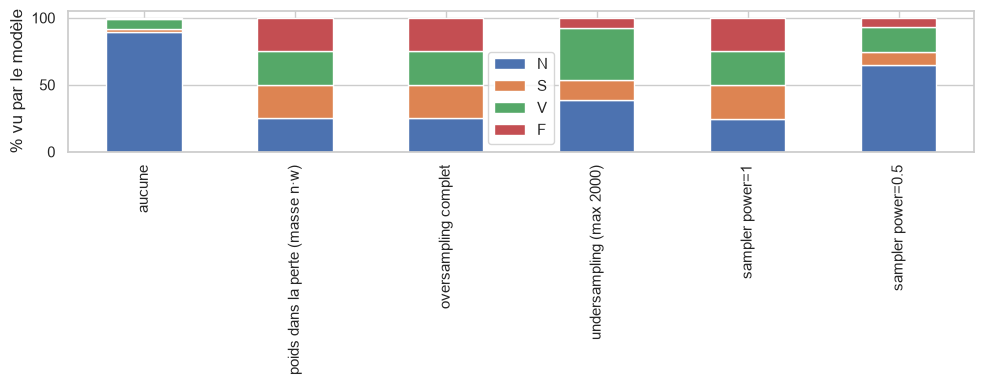

In [4]:
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
views = {
    "aucune": class_counts(y_tr, 4),
    "poids dans la perte (masse n·w)": (n * w).round().astype(int),
    "oversampling complet": class_counts(y_tr[oversample_indices(y_tr, rng)], 4),
    "undersampling (max 2000)": class_counts(y_tr[undersample_indices(y_tr, rng, 2000)], 4),
    "sampler power=1": class_counts(y_tr[np.array(list(make_weighted_sampler(y_tr, 1.0)))], 4),
    "sampler power=0.5": class_counts(y_tr[np.array(list(make_weighted_sampler(y_tr, 0.5)))], 4),
}
comp = pd.DataFrame(views, index=CLASSES).T
print(comp)
(comp.div(comp.sum(axis=1), axis=0) * 100).round(1).plot.bar(stacked=True, figsize=(10, 4))
plt.ylabel("% vu par le modèle"); plt.tight_layout(); plt.savefig(FIG_DIR / "imbalance_strategies.png", dpi=150)

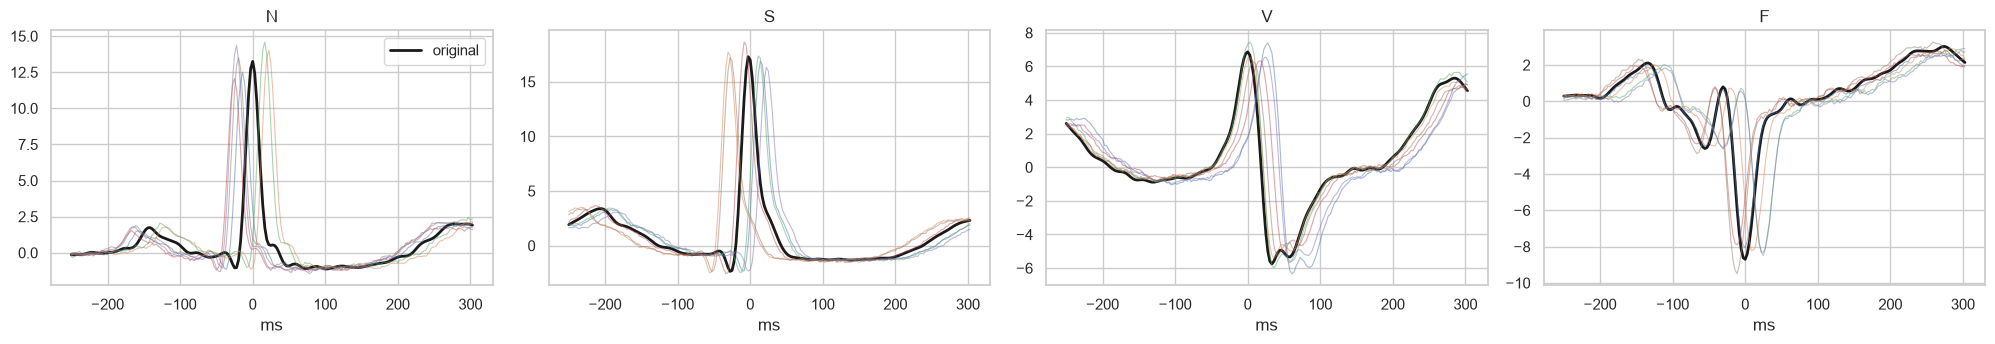

In [5]:
torch.manual_seed(SEED)
t_ms = np.arange(-P["window"]["pre"], P["window"]["post"]) / P["fs"] * 1000
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6), sharey=False)
for ax, c in zip(axes, range(4)):
    idx = np.where((split == "train") & (y == c))[0][0]
    xb = torch.tensor(X[idx])[None, None, :].repeat(6, 1, 1)
    ax.plot(t_ms, X[idx], "k", lw=2, label="original")
    for a in augment_batch(xb):
        ax.plot(t_ms, a[0].numpy(), alpha=0.5, lw=0.8)
    ax.set_title(CLASSES[c]); ax.set_xlabel("ms")
axes[0].legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "augmentation_examples.png", dpi=150)